## Explorative Data Analysis
- Read in Data from CDC-DWD for 2 German weather stations in order to determine latest frost dates

### Check data quality and consistency

In [1]:
import pandas as pd
import numpy as np

data = pd.read_csv("data/data_OBS_DEU_P1D_T5CM_N.csv", 
                   index_col=False, parse_dates=[2] )
metadata = pd.read_csv("data/sdo_OBS_DEU_P1D_T5CM_N.csv")#, index_col='SDO_Name')

print(data.columns)
print(metadata.columns)
data.info()

Index(['Produkt_Code', 'SDO_ID', 'Zeitstempel', 'Wert', 'Qualitaet_Byte',
       'Qualitaet_Niveau'],
      dtype='str')
Index(['SDO_ID', 'SDO_Name', 'Geogr_Laenge', 'Geogr_Breite', 'Hoehe_ueber_NN',
       'Metadata_Link'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 81184 entries, 0 to 81183
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Produkt_Code      81184 non-null  str           
 1   SDO_ID            81184 non-null  int64         
 2   Zeitstempel       81184 non-null  datetime64[us]
 3   Wert              81184 non-null  float64       
 4   Qualitaet_Byte    81184 non-null  int64         
 5   Qualitaet_Niveau  81184 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 3.7 MB


In [2]:
data.tail(5) #.loc[:,"Zeitstempel"]

,Produkt_Code,SDO_ID,Zeitstempel,Wert,Qualitaet_Byte,Qualitaet_Niveau
81179,OBS_DEU_P1D_T5CM_N,3987,2025-09-29,2.3,1,9
81180,OBS_DEU_P1D_T5CM_N,3987,2025-09-30,1.1,1,9
81181,OBS_DEU_P1D_T5CM_N,3987,2025-10-01,0.9,1,9
81182,OBS_DEU_P1D_T5CM_N,3987,2025-10-02,0.3,1,9
81183,OBS_DEU_P1D_T5CM_N,3987,2025-10-03,-0.5,1,9


In [3]:
metadata.tail()

,SDO_ID,SDO_Name,Geogr_Laenge,Geogr_Breite,Hoehe_ueber_NN,Metadata_Link
0,1975,Hamburg-Fuhlsbüttel,"9,9881","53,6332",11.0,https://cdc.dwd.de/rest/metadata/station/html/...
1,2700,Kösching,"11,4872","48,8302",416.0,https://cdc.dwd.de/rest/metadata/station/html/...
2,3987,Potsdam,"13,0622","52,3812",81.0,https://cdc.dwd.de/rest/metadata/station/html/...


In [4]:
# name = metadata.loc[:,'SDO_ID']
# name

In [5]:
name_map = metadata.set_index('SDO_ID')['SDO_Name'].to_dict()
df_dict = {name_map[oid]: g for oid, g in data.groupby('SDO_ID')}

In [6]:
print(name_map)
df_dict['Kösching'].head()

{1975: 'Hamburg-Fuhlsbüttel', 2700: 'Kösching', 3987: 'Potsdam'}


,Produkt_Code,SDO_ID,Zeitstempel,Wert,Qualitaet_Byte,Qualitaet_Niveau
32053,OBS_DEU_P1D_T5CM_N,2700,1961-01-01,-5.1,0,5
32054,OBS_DEU_P1D_T5CM_N,2700,1961-01-02,-1.3,0,5
32055,OBS_DEU_P1D_T5CM_N,2700,1961-01-03,-3.5,0,5
32056,OBS_DEU_P1D_T5CM_N,2700,1961-01-04,0.0,0,5
32057,OBS_DEU_P1D_T5CM_N,2700,1961-01-05,-5.0,0,5


In [7]:
# Letzter Frosttag vor dem 1. Juli
last_frost_dict = {
    ort: g[(g['Wert'] < 0) & (g['Zeitstempel'].dt.month < 7)]
          .groupby(g['Zeitstempel'].dt.year)['Zeitstempel']
          .max()
    for ort, g in df_dict.items()
}

last_frost_dict['Potsdam']

Zeitstempel
1946   1946-05-12
1947   1947-05-21
1948   1948-05-22
1949   1949-05-12
1950   1950-05-16
          ...    
2021   2021-05-08
2022   2022-04-23
2023   2023-05-03
2024   2024-04-25
2025   2025-05-08
Name: Zeitstempel, Length: 70, dtype: datetime64[us]

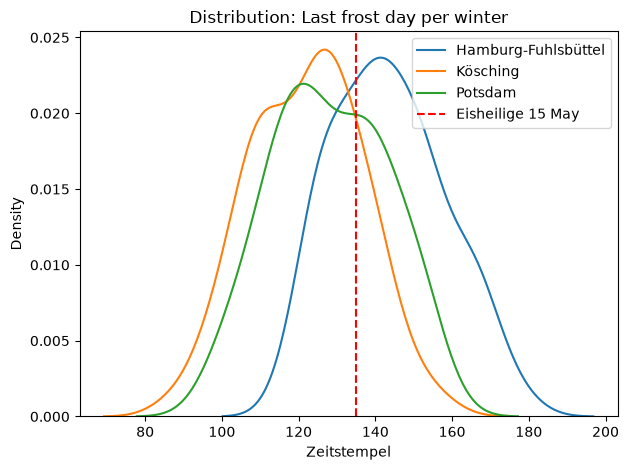

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# fig, axes = plt.subplots(1, len(last_frost_dict), figsize=(12, 4),)
#plt.xlim(1935, 2025)
# for ax in axes:
#     ax.set_xlim(60, 210)
for i,station in enumerate(last_frost_dict):
    sns.kdeplot(last_frost_dict[station].dt.day_of_year, label=station)
    # print(station)

plt.axvline(135, color='red', linestyle='--', label=f'Eisheilige 15 May')
plt.title("Distribution: Last frost day per winter")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [11]:
# print("Jahre in Hamburg mit letztem Frost bis Eisheiligen", sum(last_frost_1975.dt.day_of_year<=135))
# print("Jahre in Hamburg mit letztem Frost nach Eisheiligen", sum(last_frost_1975.dt.day_of_year>135))
# print("Jahre in Potsdam mit letztem Frost bis Eisheiligen", sum(last_frost_3987.dt.day_of_year<=135))
# print("Jahre in Potsdam mit letztem Frost nach Eisheiligen", sum(last_frost_3987.dt.day_of_year>135))

for i,station in enumerate(last_frost_dict):
    print(f"Station", station, np.median(last_frost_dict[station].dt.day_of_year)-135, 'days after Eisheilige')

Station Hamburg-Fuhlsbüttel 8.0 days after Eisheilige
Station Kösching -11.0 days after Eisheilige
Station Potsdam -8.5 days after Eisheilige


In [10]:
df_last_frost_1975 = last_frost_1975.to_frame(name='date_last_frost')   
df_last_frost_3987 = last_frost_3987.to_frame(name='date_last_frost')   

NameError: name 'last_frost_1975' is not defined

In [ ]:
for i,station in enumerate(last_frost_dict):
    # sns.lineplot(data=last_frost_dict[station].to_frame, x=last_frost_dict[station], 
    #          y=last_frost_dict[station].dt.day_of_year,
    #          markers=2);
    sns.lineplot(data=last_frost_dict[station].dt.day_of_year, label=station)

plt.legend(loc='upper right')
plt.title("Time Series: Last frost day per winter")
plt.tight_layout()
plt.show()